Кластеризация DBSCAN. Экономика городов
=============

Анализ методом DBSCAN — Economics of Cities.

**Задание.** Определить число кластеров и обосновать свой выбор. Разбить объекты на кластеры. Предложить и обосновать интерпретацию кластеров.

**Данные.** Экономические условия в 48 городах мира в 1991 году (отдел экономических исследований банка Union, Швейцария):
* `City` — название города;
* `Work` — взвешенное среднее числа рабочих часов в год по 12 профессиям;
* `Price` — индекс цен 112 товаров и услуг, включая аренду жилья (Цюрих = 100);
* `Salary` — индекс заработной платы за час работы по 12 профессиям после налогов и вычетов (Цюрих = 100).

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn import preprocessing
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [2]:
#  Задаем рабочую папку (при необходимости укажите свой путь)

# os.chdir("C:/Users/USER/Documents/Python/Lect_04/задача_2_Economics of Cities/")

## 1. Загрузка и проверка данных

Разделитель столбцов — `;`, десятичный разделитель — запятая. Названия городов используем как индекс.

In [3]:
#  Импорт данных
df = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",", index_col="City")
df.head()

,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5


In [4]:
#  Все хорошо? Посмотрим на описательные статистики
df.describe()

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


Минимум `Work` и `Salary` равен **−9999** — это код пропущенного значения, а не реальные данные. Найдём такие города.

In [5]:
df[(df == -9999).any(axis=1)]

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


У Каира и Джакарты нет данных сразу по двум из трёх признаков. Восстанавливать их не из чего, поэтому исключаем эти два города из анализа. Остаётся 46 городов.

In [6]:
df = df.replace(-9999, np.nan).dropna()
print(df.shape)
df.describe().round(1)

(46, 3)


,Work,Price,Salary
count,46.0,46.0,46.0
mean,1879.9,70.1,39.5
std,174.3,21.4,24.8
min,1583.0,30.3,2.7
25%,1745.2,51.8,14.4
50%,1849.0,70.9,43.6
75%,1976.2,81.9,59.7
max,2375.0,115.5,100.0


Посмотрим на попарные диаграммы рассеяния, чтобы заранее увидеть структуру данных.

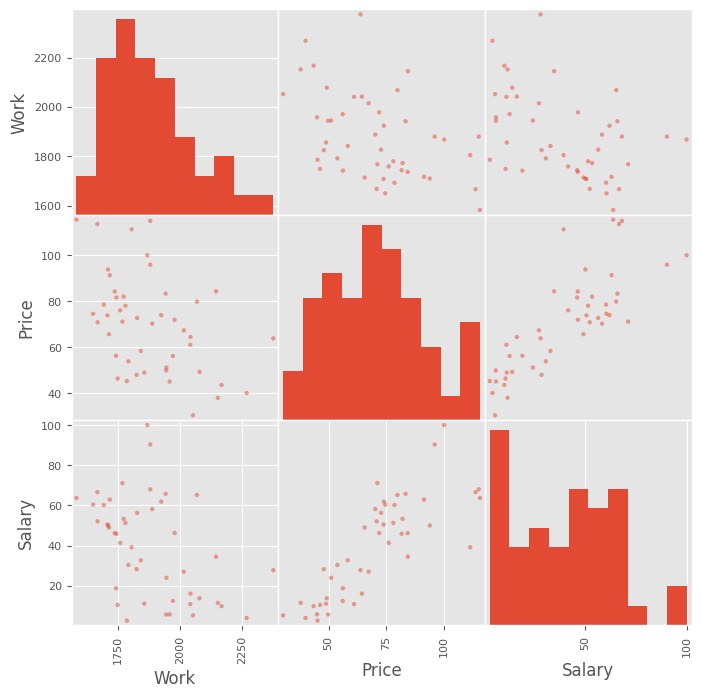

In [7]:
pd.plotting.scatter_matrix(df, figsize=(8, 8), diagonal='hist', s=40);

Видно, что `Price` и `Salary` тесно связаны (в дорогих городах выше зарплаты), а `Work` с ними связан отрицательно: в бедных городах работают больше часов.

In [8]:
df.corr().round(2)

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


## 2. Нужно ли стандартизовать данные?

**Да.** Признаки измерены в разных единицах и шкалах: `Work` — часы в год (значения порядка 1600–2400, стандартное отклонение ≈ 170), а `Price` и `Salary` — индексы (значения порядка 3–115, стандартные отклонения ≈ 20). Без стандартизации евклидово расстояние почти полностью определялось бы числом рабочих часов, а цены и зарплаты практически не влияли бы на разбиение.

Используем `StandardScaler`: приводим каждый признак к нулевому среднему и единичной дисперсии.

In [9]:
stand = preprocessing.StandardScaler()
stand.fit(df)
X = stand.transform(df)
#  Преобразуем матрицу numpy обратно в pandas.DataFrame с именами городов
X = pd.DataFrame(X, index=df.index, columns=df.columns)
X.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351


In [10]:
#  Проверка: средние ~ 0, стандартные отклонения ~ 1
X.describe().loc[['mean', 'std']].round(3)

,Work,Price,Salary
mean,0.000,-0.000,0.000
std,1.011,1.011,1.011


## 3. DBSCAN: первоначальный запуск

По аналогии с учебным примером сначала используем параметры по умолчанию (`eps=0.5`, `min_samples=5`) и посмотрим, сколько кластеров и выбросов получилось.

In [ ]:
def cluster_counts(labels):
    unique, counts = np.unique(labels, return_counts=True)
    return pd.DataFrame({'cluster': unique, 'count': counts})

dbscan_1 = DBSCAN()
dbscan_1.fit(X)
display(cluster_counts(dbscan_1.labels_))

## 4. Ручной подбор параметров

Увеличение `eps` обычно уменьшает число выбросов, но может объединить все объекты в один кластер. Уменьшение `min_samples` ослабляет требование к плотности. Сравним несколько вариантов.

In [ ]:
trial_params = [(0.5, 5), (0.75, 5), (1.0, 5), (0.75, 3), (1.0, 3)]
manual_results = []
for eps, min_samples in trial_params:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    manual_results.append({'eps': eps, 'min_samples': min_samples,
                           'n_clusters': len(set(labels) - {-1}),
                           'n_noise': int(sum(labels == -1))})
display(pd.DataFrame(manual_results))

## 5. Автоматический подбор параметров по Silhouette Score

Как в примере преподавателя, переберём сетку `eps` и `min_samples` и найдём максимальный силуэт. Здесь силуэт считается **по всем объектам, включая шум с меткой −1**, как в исходном примере. Отдельно покажем силуэт без шумовых объектов, чтобы результат было проще интерпретировать. Важно: наличие метки −1 не означает, что шум является полноценным кластером.

In [ ]:
from sklearn.metrics import silhouette_score

eps_1 = [0.45, 0.5, 0.6, 0.75, 0.9, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75, 3]
min_samples_1 = [2, 3, 4, 5, 6, 7, 8, 9, 10]

search_results = []
for eps in eps_1:
    for min_samples in min_samples_1:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        n_clusters = len(set(labels) - {-1})
        n_noise = int(sum(labels == -1))
        # Как в учебном примере: силуэт по всем меткам, включая -1
        sil_all = silhouette_score(X, labels) if 2 <= len(set(labels)) < len(X) and n_clusters >= 2 else np.nan
        # Дополнительная проверка: силуэт только по кластеризованным объектам
        mask = labels != -1
        sil_clean = (silhouette_score(X.loc[mask], labels[mask])
                     if n_clusters >= 2 and mask.sum() > n_clusters else np.nan)
        search_results.append({'eps': eps, 'min_samples': min_samples,
                               'n_clusters': n_clusters, 'n_noise': n_noise,
                               'silhouette_all': sil_all,
                               'silhouette_without_noise': sil_clean})
search_results = pd.DataFrame(search_results)
display(search_results.sort_values('silhouette_all', ascending=False).head(15).round(3))

Максимальный силуэт не всегда означает наиболее содержательное разбиение: отдельно проверим число шумовых объектов. Для основного анализа выберем лучший вариант среди решений, где не более 25% наблюдений отнесено к шуму. Это дополнительное практическое ограничение, а не часть DBSCAN.

In [ ]:
candidates = search_results[(search_results.n_clusters >= 2) &
                            (search_results.n_noise <= len(X) * 0.25) &
                            search_results.silhouette_all.notna()]
if candidates.empty:
    candidates = search_results[(search_results.n_clusters >= 2) & search_results.silhouette_all.notna()]
if candidates.empty:
    raise ValueError('В заданной сетке не найдено разбиений с двумя или более кластерами')
best = candidates.sort_values('silhouette_all', ascending=False).iloc[0]
eps = float(best.eps)
min_samples = int(best.min_samples)
print(f'Выбрано eps={eps}, min_samples={min_samples}')
print(f'Кластеров: {int(best.n_clusters)}, выбросов: {int(best.n_noise)}')
print(f'Silhouette Score (все объекты): {best.silhouette_all:.3f}')
print(f'Silhouette Score (без шума): {best.silhouette_without_noise:.3f}')

## 6. Результаты кластеризации

In [ ]:
dbscan_best = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean')
labels = dbscan_best.fit_predict(X)
result = df.copy()
result['dbscan'] = labels
display(cluster_counts(labels))
for cluster, group in result.groupby('dbscan'):
    print(('Шум' if cluster == -1 else f'Кластер {cluster}') + ':', ', '.join(group.index))

In [ ]:
print('Средние исходные показатели по группам:')
display(result.groupby('dbscan')[['Work', 'Price', 'Salary']].mean().round(1))
print('Средние стандартизованные показатели:')
display(X.assign(dbscan=labels).groupby('dbscan').mean().round(2))

In [ ]:
X.assign(dbscan=labels).groupby('dbscan').mean().T.plot(kind='bar', figsize=(9, 5), rot=0)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Профили групп DBSCAN (−1 — шум)')
plt.ylabel('Стандартизованные значения')
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
for cl, group in result.groupby('dbscan'):
    ax.scatter(group.Price, group.Salary, label='Шум' if cl == -1 else f'Кластер {cl}', alpha=0.8)
for city, r in result.iterrows():
    ax.annotate(city, (r.Price, r.Salary), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set(xlabel='Price', ylabel='Salary', title='Результат DBSCAN: Price и Salary')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Сравнение с иерархической кластеризацией

Как в учебном примере, сравним распределение объектов между DBSCAN и методом Уорда. Число групп для метода Уорда зададим равным числу кластеров DBSCAN (без шума).

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster
n_clusters = len(set(labels) - {-1})
link = linkage(X, method='ward', metric='euclidean')
hier_labels = fcluster(link, t=n_clusters, criterion='maxclust')
print('Таблица сопряжённости:')
display(pd.crosstab(pd.Series(labels, name='DBSCAN'),
                    pd.Series(hier_labels, name='Ward')))
print('Средние показатели групп метода Уорда:')
display(df.assign(ward=hier_labels).groupby('ward').mean().round(1))

## 8. Выводы

После удаления строк с пропущенными значениями кластеризация проведена по трём стандартизованным признакам: `Work`, `Price` и `Salary`. DBSCAN позволяет выделять плотные группы городов и отмечать шумовые наблюдения.

Параметры `eps` и `min_samples` исследованы вручную и с помощью перебора по сетке с Silhouette Score, по аналогии с учебным ноутбуком. Окончательное разбиение выбирается с дополнительным ограничением на долю шума. Количество найденных кластеров, шумовых объектов и конкретные экономические различия следует описывать по таблицам выше после выполнения ячеек.

Сопоставление с методом Уорда показывает, насколько устойчиво выделяются группы при изменении алгоритма. При этом результаты не обязаны совпадать: DBSCAN использует плотность, а метод Уорда — увеличение внутрикластерной суммы квадратов.